<a href="https://colab.research.google.com/github/manyaAM123/deep_learning/blob/main/exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


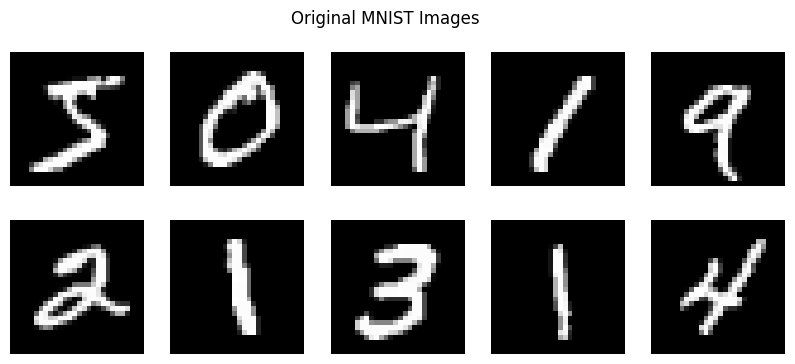


Autoencoder Model Summary


Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 784)            │       101,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.2414 - val_loss: 0.1621
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1459 - val_loss: 0.1334
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1287 - val_loss: 0.1219
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1192 - val_loss: 0.1139
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1125 - val_loss: 0.1089
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1082 - val_loss: 0.1053
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1053 - val_loss: 0.1030
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1030 - val_loss: 0.1007
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1009 - val_loss: 0.0988
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0991 - val_loss: 0.0971
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step


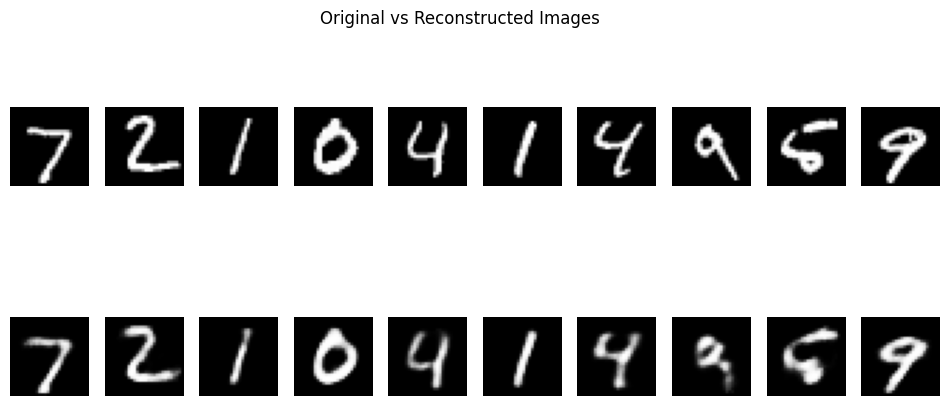

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


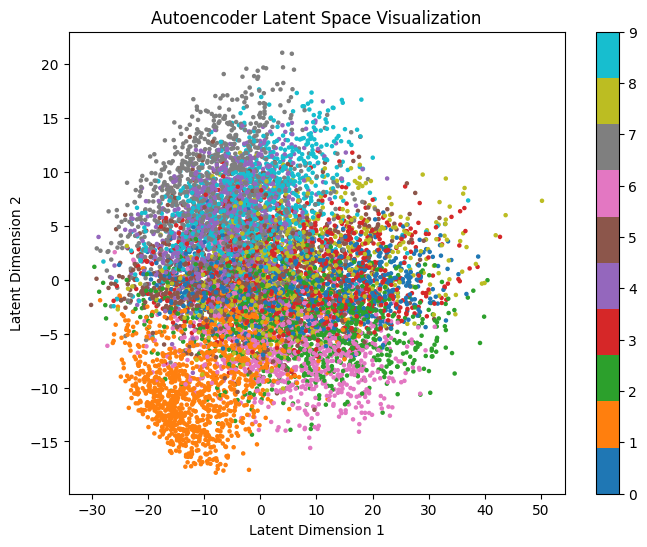

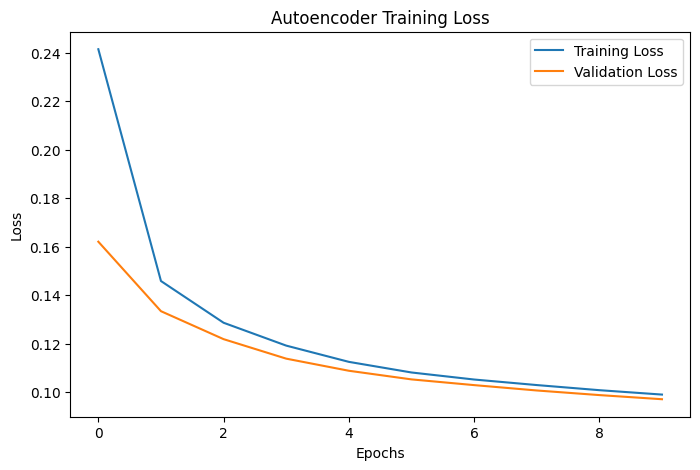

Basic Autoencoder Completed Successfully!


In [17]:
# ================================================
# BASIC AUTOENCODER USING MNIST DATASET
# ================================================

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Reshape

# 2. Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

# 3. Normalize Images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 4. Display Original Images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Original MNIST Images")
plt.show()

# 5. Build Encoder
input_img = Input(shape=(28, 28))

flat = Flatten()(input_img)

encoded = Dense(128, activation="relu")(flat)
encoded = Dense(64, activation="relu")(encoded)

# Bottleneck Layer
latent = Dense(32, activation="relu",
               name="latent_space")(encoded)

# 6. Build Decoder
decoded = Dense(64, activation="relu")(latent)
decoded = Dense(128, activation="relu")(decoded)

output = Dense(784, activation="sigmoid")(decoded)

output_img = Reshape((28, 28))(output)

# 7. Create Autoencoder Model
autoencoder = Model(input_img, output_img)

# 8. Create Encoder Model
encoder = Model(input_img, latent)

# 9. Compile Model
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

print("\nAutoencoder Model Summary")
autoencoder.summary()

# 10. Train Model
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# 11. Reconstruct Images
reconstructed = autoencoder.predict(x_test[:10])

# 12. Display Original and Reconstructed Images
plt.figure(figsize=(12, 5))

for i in range(10):

    # Original Image
    plt.subplot(2, 10, i+1)
    plt.imshow(x_test[i], cmap="gray")
    plt.axis("off")

    # Reconstructed Image
    plt.subplot(2, 10, i+11)
    plt.imshow(reconstructed[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed Images")
plt.show()

# 13. Visualize Latent Space Using PCA
from sklearn.decomposition import PCA

latent_features = encoder.predict(x_test)

pca = PCA(n_components=2)

latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))

plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test,
    cmap="tab10",
    s=5
)

plt.colorbar()
plt.title("Autoencoder Latent Space Visualization")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

# 14. Plot Training Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("Basic Autoencoder Completed Successfully!")



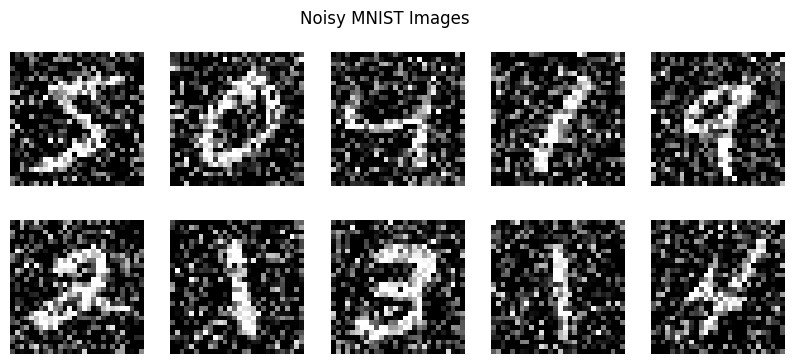


Denoising Autoencoder Summary


Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 784)            │       101,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.2629 - val_loss: 0.1935
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1786 - val_loss: 0.1661
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1592 - val_loss: 0.1513
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1479 - val_loss: 0.1425
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1411 - val_loss: 0.1371
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1363 - val_loss: 0.1331
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1328 - val_loss: 0.1304
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1305 - val_loss: 0.1286
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1288 - val_loss: 0.1272
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1273 - val_loss: 0.1259
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step


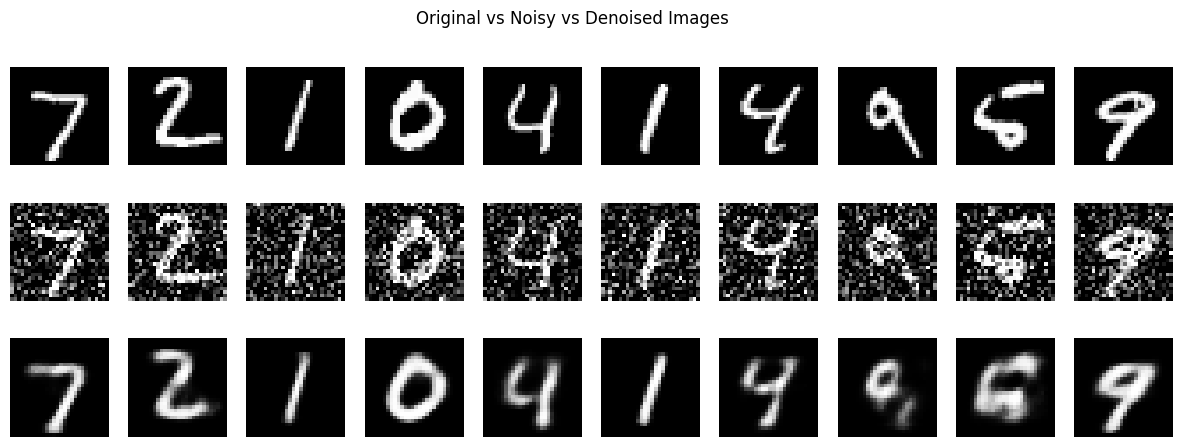

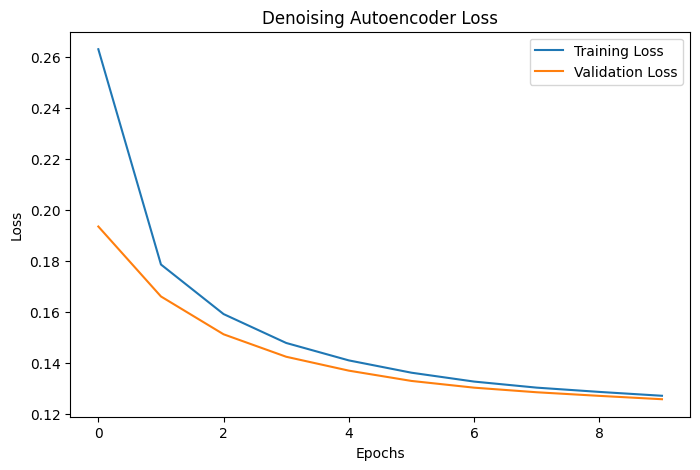

Denoising Autoencoder Completed Successfully!


In [18]:
# ================================================
# DENOISING AUTOENCODER USING MNIST DATASET
# ================================================

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Reshape

# 2. Load Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 3. Normalize Data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 4. Add Gaussian Noise
noise_factor = 0.4

x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_test.shape
)

# Clip Values Between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

# 5. Display Noisy Images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train_noisy[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Noisy MNIST Images")
plt.show()

# 6. Build Encoder
input_img = Input(shape=(28, 28))

flat = Flatten()(input_img)

encoded = Dense(128, activation="relu")(flat)
encoded = Dense(64, activation="relu")(encoded)

latent = Dense(32, activation="relu")(encoded)

# 7. Build Decoder
decoded = Dense(64, activation="relu")(latent)
decoded = Dense(128, activation="relu")(decoded)

output = Dense(784, activation="sigmoid")(decoded)

output_img = Reshape((28, 28))(output)

# 8. Create Denoising Autoencoder
dae = Model(input_img, output_img)

# 9. Compile Model
dae.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

print("\nDenoising Autoencoder Summary")
dae.summary()

# 10. Train Model
history = dae.fit(
    x_train_noisy,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

# 11. Reconstruct Clean Images
denoised = dae.predict(x_test_noisy[:10])

# 12. Display Comparison
plt.figure(figsize=(15, 5))

for i in range(10):

    # Original
    plt.subplot(3, 10, i+1)
    plt.imshow(x_test[i], cmap="gray")
    plt.axis("off")

    # Noisy
    plt.subplot(3, 10, i+11)
    plt.imshow(x_test_noisy[i], cmap="gray")
    plt.axis("off")

    # Denoised
    plt.subplot(3, 10, i+21)
    plt.imshow(denoised[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Original vs Noisy vs Denoised Images")
plt.show()

# 13. Plot Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Denoising Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("Denoising Autoencoder Completed Successfully!")




Encoder Summary


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16      │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 784)       │          0 │ input_layer_16[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_31 (Dense)    │ (None, 256)       │    200,960 │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 128)       │     32,896 │ dense_31[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ dense_32[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ dense_32[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 234,372 (915.52 KB)

 Trainable params: 234,372 (915.52 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 234,896 (917.56 KB)

 Trainable params: 234,896 (917.56 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - kl_loss: 5.1090 - loss: 193.5490 - reconstruction_loss: 188.4398 - val_kl_loss: 0.0000e+00 - val_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 4.8191 - loss: 166.9819 - reconstruction_loss: 162.1629 - val_kl_loss: 0.0000e+00 - val_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 5.2523 - loss: 160.8280 - reconstruction_loss: 155.5757 - val_kl_loss: 0.0000e+00 - val_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 5.5229 - loss: 157.1439 - reconstruction_loss: 151.6210 - val_kl_loss: 0.0000e+00 - val_loss: 0.0000e+00 - val_reconstruction_loss: 0.0000e+00
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - kl_loss: 5.6705 - loss: 154.7906 - reconstruction_loss: 149.1202 - val_kl_loss: 0.0000e+00 - val_loss: 0.0000e+00 - val_

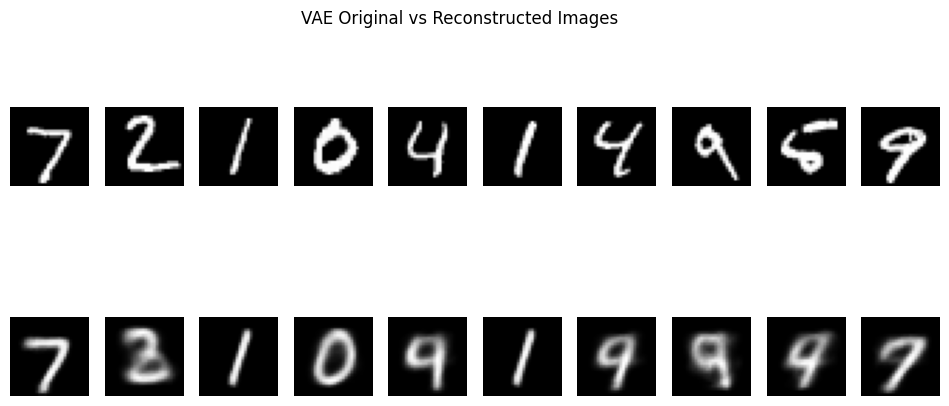

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


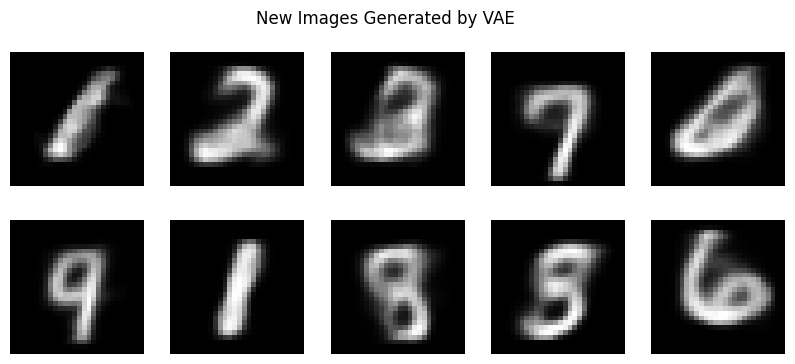

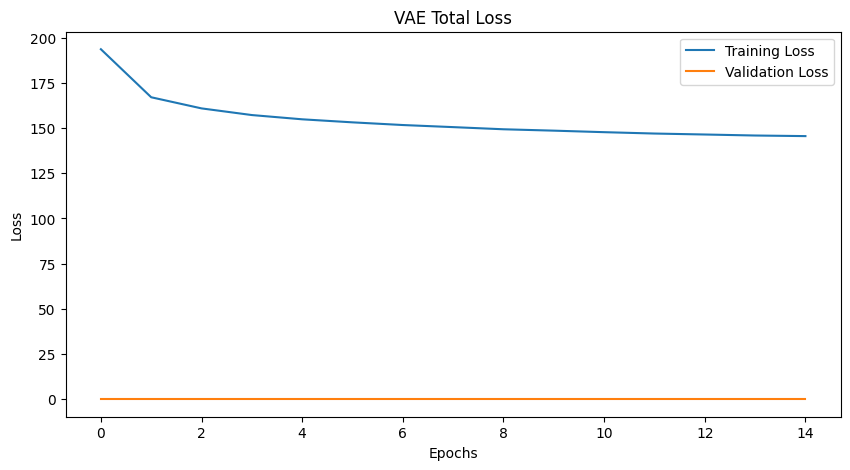

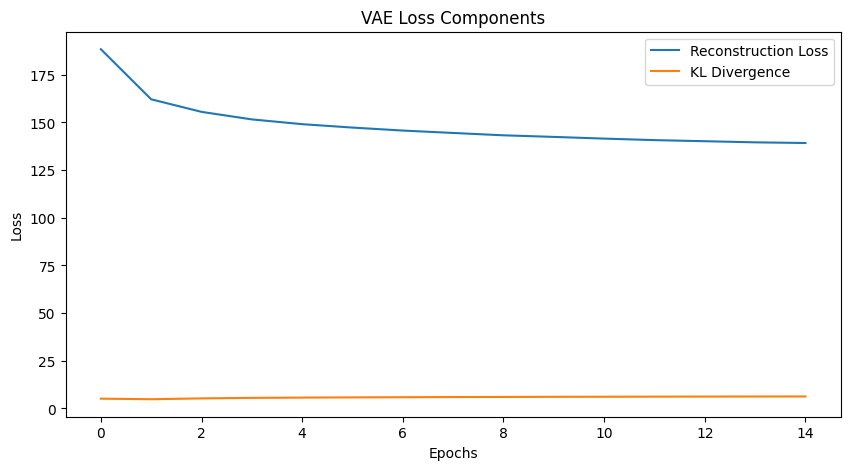

Variational Autoencoder Completed Successfully!


In [19]:
# ================================================
# VARIATIONAL AUTOENCODER (VAE) USING MNIST
# ================================================

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import (
    Input, Dense, Flatten, Reshape, Layer
)
from tensorflow.keras.models import Model

# 2. Load Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 3. Normalize Images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# 4. Set Latent Dimension
latent_dim = 2

# 5. Sampling Layer (Reparameterization Trick)
class Sampling(Layer):

    def call(self, inputs):

        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(
            shape=tf.shape(z_mean)
        )

        return z_mean + tf.exp(
            0.5 * z_log_var
        ) * epsilon

# 6. Build Encoder
encoder_input = Input(shape=(28, 28, 1))

x = Flatten()(encoder_input)
x = Dense(256, activation="relu")(x)
x = Dense(128, activation="relu")(x)

# Mean and Log Variance
z_mean = Dense(latent_dim, name="z_mean")(x)

z_log_var = Dense(
    latent_dim,
    name="z_log_var"
)(x)

# Sample Latent Vector
z = Sampling()([z_mean, z_log_var])

encoder = Model(
    encoder_input,
    [z_mean, z_log_var, z],
    name="encoder"
)

print("\nEncoder Summary")
encoder.summary()

# 7. Build Decoder
latent_input = Input(shape=(latent_dim,))

x = Dense(128, activation="relu")(latent_input)
x = Dense(256, activation="relu")(x)

x = Dense(784, activation="sigmoid")(x)

decoder_output = Reshape((28, 28, 1))(x)

decoder = Model(
    latent_input,
    decoder_output,
    name="decoder"
)

print("\nDecoder Summary")
decoder.summary()

# 8. Create VAE Model
class VAE(Model):

    def __init__(self, encoder, decoder, **kwargs):

        super().__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = tf.keras.metrics.Mean(
            name="loss"
        )

        self.reconstruction_loss_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )

        self.kl_loss_tracker = tf.keras.metrics.Mean(
            name="kl_loss"
        )

    @property
    def metrics(self):

        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):

        x, _, _ = tf.keras.utils.unpack_x_y_sample_weight(data)

        with tf.GradientTape() as tape:

            z_mean, z_log_var, z = self.encoder(
                x,
                training=True
            )

            reconstruction = self.decoder(
                z,
                training=True
            )

            # Reconstruction Loss
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        x,
                        reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            # KL Divergence
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            # Total Loss
            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)

        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )

        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result()
        }

    def test_step(self, data):

        x, _, _ = tf.keras.utils.unpack_x_y_sample_weight(data)

        z_mean, z_log_var, z = self.encoder(
            x,
            training=False
        )

        reconstruction = self.decoder(
            z,
            training=False
        )

        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(
                    x,
                    reconstruction
                ),
                axis=(1, 2)
            )
        )

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var),
                axis=1
            )
        )

        total_loss = reconstruction_loss + kl_loss

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }

    def call(self, inputs, training=False):

        _, _, z = self.encoder(
            inputs,
            training=training
        )

        return self.decoder(
            z,
            training=training
        )

# 9. Create VAE
vae = VAE(encoder, decoder)

# 10. Compile Model
vae.compile(
    optimizer=tf.keras.optimizers.Adam()
)

# 11. Train Model
history = vae.fit(
    x_train,
    epochs=15,
    batch_size=128,
    validation_data=(x_test, x_test),
    verbose=1
)

# 12. Reconstruct Images
z_mean_test, z_log_var_test, z_test = encoder.predict(
    x_test[:10]
)

reconstructed = decoder.predict(z_test)

# 13. Display Original and Reconstructed Images
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 10, i+1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")

    plt.subplot(2, 10, i+11)
    plt.imshow(reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("VAE Original vs Reconstructed Images")
plt.show()

# 14. Generate New Images
random_latent = np.random.normal(
    size=(10, latent_dim)
).astype("float32")

generated_images = decoder.predict(random_latent)

# 15. Display Generated Images
plt.figure(figsize=(10, 4))

for i in range(10):

    plt.subplot(2, 5, i+1)

    plt.imshow(
        generated_images[i].squeeze(),
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("New Images Generated by VAE")
plt.show()

# 16. Plot Training Loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("VAE Total Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 17. Plot Reconstruction and KL Loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["reconstruction_loss"],
    label="Reconstruction Loss"
)

plt.plot(
    history.history["kl_loss"],
    label="KL Divergence"
)

plt.title("VAE Loss Components")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

print("Variational Autoencoder Completed Successfully!")

